--- BẢNG TÍNH TOÁN VÍ DỤ 5.5 ---
 j    x_j   p_j    z_j
 1  5.510 0.020 -2.054
 2  6.060 0.060 -1.555
 3  6.170 0.100 -1.282
 4  8.520 0.140 -1.080
 5  8.790 0.180 -0.915
 6  9.830 0.220 -0.772
 7  9.950 0.260 -0.643
 8  9.960 0.300 -0.524
 9 10.060 0.340 -0.412
10 10.150 0.380 -0.305
11 10.770 0.420 -0.202
12 10.870 0.460 -0.100
13 11.070 0.500  0.000
14 11.120 0.540  0.100
15 11.250 0.580  0.202
16 11.270 0.620  0.305
17 11.310 0.660  0.412
18 11.810 0.700  0.524
19 11.890 0.740  0.643
20 12.020 0.780  0.772
21 12.080 0.820  0.915
22 13.920 0.860  1.080
23 13.950 0.900  1.282
24 14.640 0.940  1.555
25 15.670 0.980  2.054

--- KẾT QUẢ ƯỚC LƯỢNG VÍ DỤ 5.5 ---
Trung bình mẫu (x_bar)    : 10.75
Độ lệch chuẩn mẫu (s)     : 2.49
Giá trị t_(24; 0.025)     : 2.0639
Sai số ước lượng          : 1.03
Khoảng tin cậy 95% của mu : (9.72 < mu < 11.77)


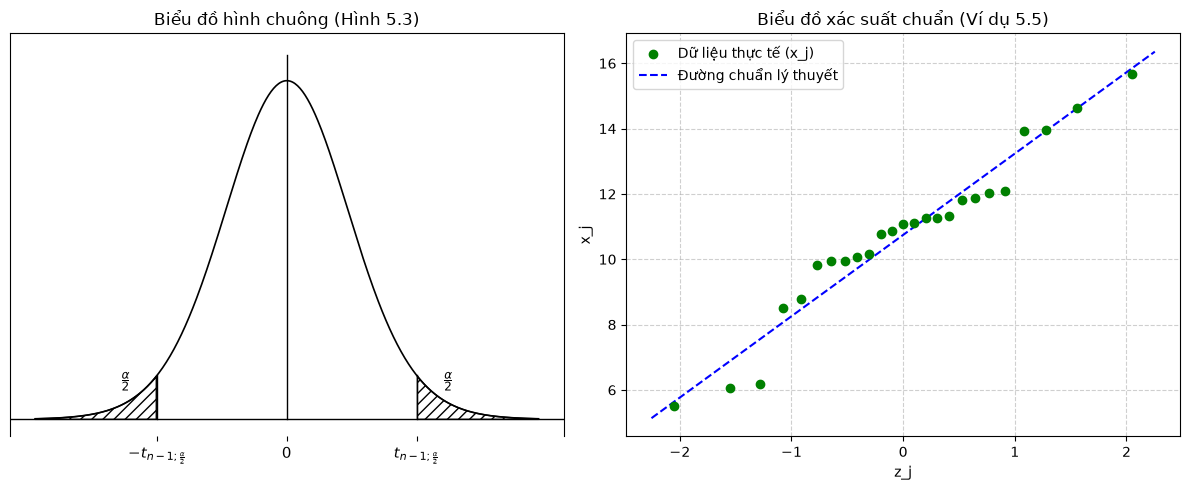

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t

# 1. Khai báo trực tiếp 25 số liệu gốc từ đề bài Ví dụ 5.5 và sắp xếp tăng dần
data_goc = [
    6.06, 11.07, 10.77, 15.67, 10.15, 
    5.51, 10.87, 12.02, 12.08, 6.17, 
    9.96, 9.95, 13.95, 10.06, 11.25, 
    8.79, 8.52, 11.31, 13.92, 11.81, 
    11.27, 11.12, 11.89, 14.64, 9.83
]
x_j = np.sort(data_goc)

# 2. Tính các đại lượng đặc trưng mẫu
n = len(x_j)
x_bar = np.mean(x_j)
s = np.std(x_j, ddof=1)

# 3. Tính bảng thông số cho Biểu đồ xác suất chuẩn
j = np.arange(1, n + 1)
p_j = (j - 0.5) / n
z_j = norm.ppf(p_j)

df = pd.DataFrame({'j': j, 'x_j': x_j, 'p_j': p_j, 'z_j': z_j})
print("--- BẢNG TÍNH TOÁN VÍ DỤ 5.5 ---")
print(df.to_string(index=False, float_format="%.3f"))

# 4. Tính khoảng tin cậy 95% (Phân phối Student t với bậc tự do df = n - 1 = 24)
alpha = 0.05
t_alpha_2 = t.ppf(1 - alpha / 2, df=n - 1)
sai_so = t_alpha_2 * (s / np.sqrt(n))

print(f"\n--- KẾT QUẢ ƯỚC LƯỢNG VÍ DỤ 5.5 ---")
print(f"Trung bình mẫu (x_bar)    : {x_bar:.2f}")
print(f"Độ lệch chuẩn mẫu (s)     : {s:.2f}")
print(f"Giá trị t_(24; 0.025)     : {t_alpha_2:.4f}")
print(f"Sai số ước lượng          : {sai_so:.2f}")
print(f"Khoảng tin cậy 95% của mu : ({x_bar - sai_so:.2f} < mu < {x_bar + sai_so:.2f})")

# 5. Vẽ biểu đồ
plt.figure(figsize=(12, 5))

# Biểu đồ 1: Biểu đồ hình chuông kết hợp Histogram thực tế
#plt.subplot(1, 2, 1)
#plt.hist(x_j, bins=6, density=True, alpha=0.5, color='skyblue', edgecolor='black', label='Tần suất thực tế')
#x_bell = np.linspace(min(x_j) - 2, max(x_j) + 2, 200)
#plt.plot(x_bell, norm.pdf(x_bell, x_bar, s), 'r-', lw=2, label='Đường cong chuẩn N(x_bar, s²)')
#plt.title('Biểu đồ hình chuông (Ví dụ 5.5)')
#plt.xlabel('Hàm lượng asen (10⁻³ mg/l)')
#plt.ylabel('Mật độ xác suất')
#plt.legend()
#plt.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 1: Biểu đồ hình chuông giống Hình 5.3 trong sách
ax1 = plt.subplot(1, 2, 1)

# 1. Tạo trục t và đường cong phân phối Student (bậc tự do n - 1)
t_val = np.linspace(-4, 4, 400)
y_val = t.pdf(t_val, df=n - 1)
plt.plot(t_val, y_val, color='black', lw=1.2)

# 2. Vẽ đường trục ngang (y = 0) và trục đối xứng dọc (x = 0)
plt.axhline(0, color='black', lw=1)
plt.plot([0, 0], [0, t.pdf(0, df=n - 1) + 0.03], color='black', lw=1)

# 3. Gạch chéo (hatch='///') 2 phần đuôi nằm ngoài khoảng tin cậy
plt.fill_between(t_val, 0, y_val, where=(t_val <= -t_alpha_2), 
                 facecolor='none', edgecolor='black', hatch='///')
plt.fill_between(t_val, 0, y_val, where=(t_val >= t_alpha_2), 
                 facecolor='none', edgecolor='black', hatch='///')

# 4. Vẽ 2 đoạn thẳng đứng giới hạn tại -t và +t
plt.plot([-t_alpha_2, -t_alpha_2], [0, t.pdf(-t_alpha_2, df=n - 1)], color='black', lw=1)
plt.plot([t_alpha_2, t_alpha_2], [0, t.pdf(t_alpha_2, df=n - 1)], color='black', lw=1)

# 5. Ghi ký hiệu α/2 và các mốc tọa độ giống hệt sách giáo trình
plt.text(-t_alpha_2 - 0.5, 0.04, r'$\frac{\alpha}{2}$', fontsize=12, ha='center')
plt.text(t_alpha_2 + 0.5, 0.04, r'$\frac{\alpha}{2}$', fontsize=12, ha='center')

plt.xticks([-t_alpha_2, 0, t_alpha_2], [r'$-t_{n-1;\frac{\alpha}{2}}$', '0', r'$t_{n-1;\frac{\alpha}{2}}$'], fontsize=11)
plt.yticks([]) # Ẩn số trên trục tung như trong sách
ax1.spines['bottom'].set_visible(False) # Ẩn viền dưới mặc định để nhãn nằm sát trục y=0
plt.ylim(-0.02, 0.45)
plt.title('Biểu đồ hình chuông (Hình 5.3)')

# Biểu đồ 2: Biểu đồ xác suất chuẩn (vẽ đường thẳng bằng 2 điểm đầu - cuối)
plt.subplot(1, 2, 2)
plt.scatter(z_j, x_j, color='green', zorder=5, label='Dữ liệu thực tế (x_j)')
z_ends = np.array([min(z_j) - 0.2, max(z_j) + 0.2])
plt.plot(z_ends, s * z_ends + x_bar, 'b--', label='Đường chuẩn lý thuyết')
plt.title('Biểu đồ xác suất chuẩn (Ví dụ 5.5)')
plt.xlabel('z_j')
plt.ylabel('x_j')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()